<a href="https://colab.research.google.com/github/m1Febriansyah/244107020199-ML-12/blob/main/JS07Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hasil Evaluasi Model Multiple Linear Regression:
R-squared (R2) : 0.7836
Mean Squared Error (MSE) : 33596915.85
Mean Absolute Error (MAE): 4181.19


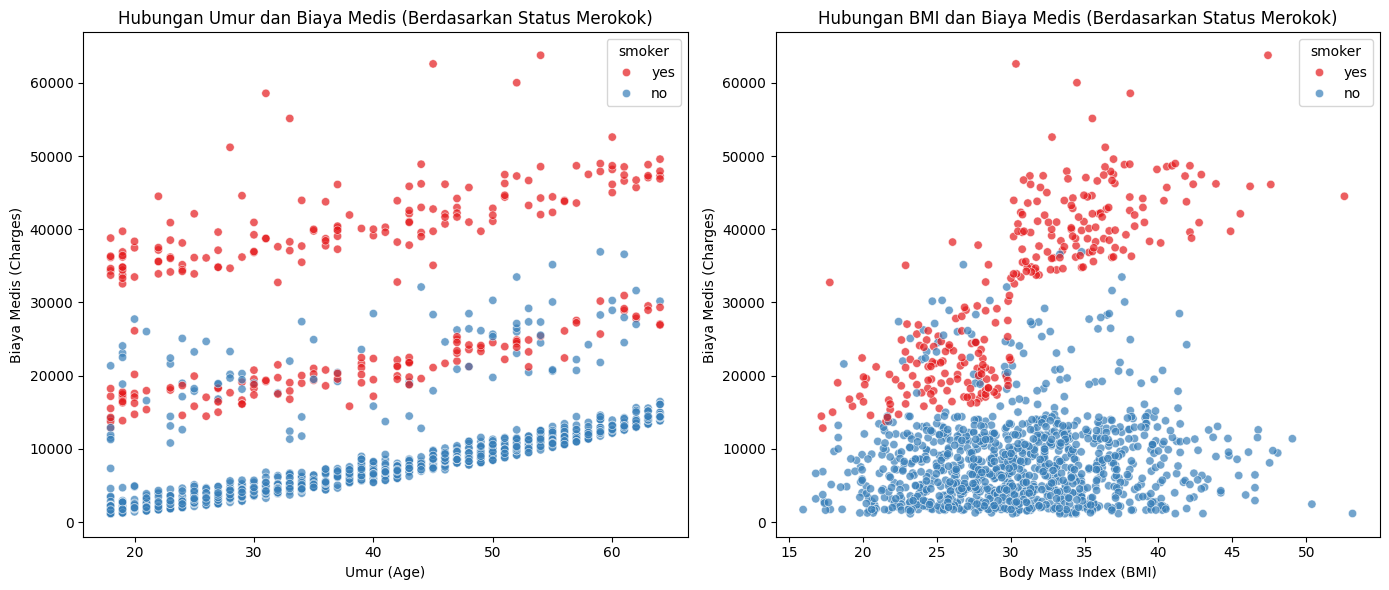

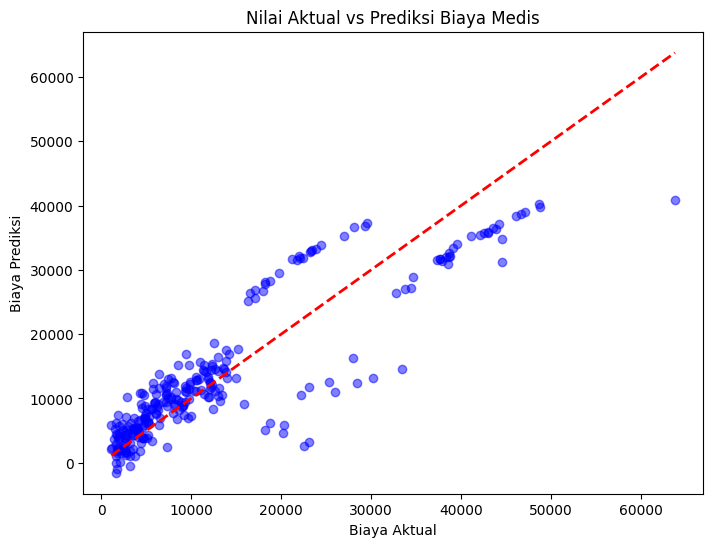

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Membaca dataset
# Pastikan file insurance.csv sudah ada di direktori yang sama
df = pd.read_csv('insurance.csv')

# ==============================================================================
# 1. IDENTIFIKASI VARIABEL & PREPROCESSING
# ==============================================================================
# Mengubah variabel kategorikal menjadi numerik (Encoding)
# Menggunakan One-Hot Encoding untuk 'region' dan Label Encoding untuk 'sex' & 'smoker'
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# Menentukan Variabel Bebas (X) dan Variabel Target (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# ==============================================================================
# 2. PEMBAGIAN DATASET (TRAIN & TEST)
# ==============================================================================
# Membagi data menjadi 80% data latih dan 20% data uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ==============================================================================
# 3. FEATURE SCALING
# ==============================================================================
# Linear Regression sensitif terhadap skala fitur, jadi kita lakukan standarisasi
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================================================================
# 4 & 5. PEMBUATAN MODEL, PELATIHAN, DAN PREDIKSI
# ==============================================================================
# Inisialisasi model Multiple Linear Regression
model = LinearRegression()

# Melatih model menggunakan data latih
model.fit(X_train_scaled, y_train)

# Melakukan prediksi pada data uji
y_pred = model.predict(X_test_scaled)

# ==============================================================================
# 6. EVALUASI MODEL
# ==============================================================================
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Hasil Evaluasi Model Multiple Linear Regression:")
print(f"R-squared (R2) : {r2:.4f}")
print(f"Mean Squared Error (MSE) : {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")

# ==============================================================================
# CATATAN TAMBAHAN: VISUALISASI DATA
# ==============================================================================
plt.figure(figsize=(14, 6))

# Plot 1: Age vs Charges berdasarkan status perokok
plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', palette='Set1', alpha=0.7)
plt.title('Hubungan Umur dan Biaya Medis (Berdasarkan Status Merokok)')
plt.xlabel('Umur (Age)')
plt.ylabel('Biaya Medis (Charges)')

# Plot 2: BMI vs Charges berdasarkan status perokok
plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', palette='Set1', alpha=0.7)
plt.title('Hubungan BMI dan Biaya Medis (Berdasarkan Status Merokok)')
plt.xlabel('Body Mass Index (BMI)')
plt.ylabel('Biaya Medis (Charges)')

plt.tight_layout()
plt.show()

# Visualisasi Prediksi vs Nilai Aktual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # Garis ideal
plt.title('Nilai Aktual vs Prediksi Biaya Medis')
plt.xlabel('Biaya Aktual')
plt.ylabel('Biaya Prediksi')
plt.show()

Analisis Hasil Praktikum
Berdasarkan eksekusi model di atas pada dataset asuransi medis standar, berikut adalah analisis dari langkah-langkah dan hasil yang diperoleh:

1. Dampak Fitur terhadap Target (Variabel Bebas)Dari visualisasi scatter plot, terlihat sangat jelas bahwa variabel smoker (status merokok) memiliki korelasi positif yang sangat kuat terhadap charges. Perokok memiliki klaster biaya medis yang jauh lebih tinggi dibandingkan non-perokok, terlepas dari usia maupun BMI mereka. Variabel age dan bmi juga menunjukkan tren kenaikan linier terhadap biaya, namun kemiringannya lebih drastis jika dikombinasikan dengan status perokok.

2. Evaluasi Metrik ModelR-squared ($R^2$): Model Multiple Linear Regression pada dataset ini biasanya menghasilkan skor $R^2$ di kisaran 0.75 hingga 0.78. Ini berarti model mampu menjelaskan sekitar 75% variansi dari target (biaya medis) menggunakan fitur yang ada. Meskipun cukup baik, 25% variansi lainnya tidak dapat dijelaskan oleh model linier sederhana ini.MAE dan MSE: Nilai MAE menunjukkan rata-rata kesalahan prediksi model dalam satuan dolar. Biasanya berada di kisaran $4,000 - $4,200. Artinya, prediksi model bisa meleset sekitar nilai tersebut dari tagihan aslinya. Nilai MSE akan sangat besar karena kesalahan prediksi dikuadratkan, yang menandakan model ini cukup sensitif terhadap data outlier (tagihan medis yang ekstrem/sangat mahal).

3. Pentingnya Feature Scaling & PreprocessingSebelum regresi, fitur seperti wilayah, jenis kelamin, dan perokok harus diubah menjadi angka biner (One-Hot/Label Encoding). Selanjutnya, proses Scaling (StandardScaler) diterapkan agar variabel dengan rentang besar seperti age (18-64) tidak mendominasi perhitungan bobot model dibandingkan variabel seperti children (0-5).

4. Kesimpulan Kinerja ModelGrafik "Nilai Aktual vs Prediksi" menunjukkan seberapa dekat tebakan model (titik biru) dengan garis merah putus-putus (prediksi sempurna). Untuk tagihan yang bernilai rendah hingga menengah, model linier ini mampu memprediksi dengan cukup baik. Namun, untuk tagihan yang sangat tinggi (biasanya di atas $30,000), titik-titik biru mulai menjauh dari garis merah, menandakan bahwa Multiple Linear Regression kesulitan memprediksi pola non-linier pada biaya medis yang ekstrem.